In [267]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

In [268]:
np.random.seed(42)

In [269]:
xy = loadmat ("data/data1.mat")["data1"]
x, y = xy[0], xy[1]
d = loadmat("data/eng_signals.mat")
eng = [d[f"eng_signal{k}"].ravel().astype(float) for k in (1,2,3)]
fs = 500.0
t = np.arange(eng[0].size) / fs

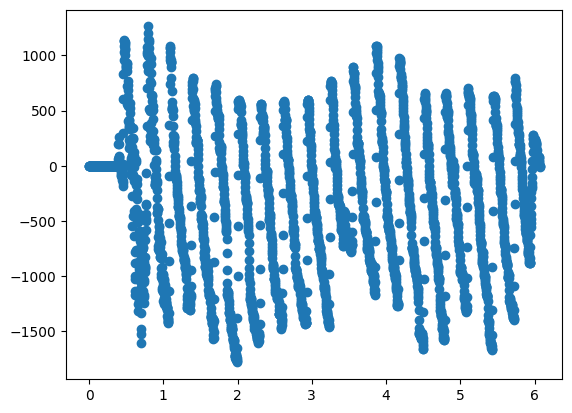

In [270]:
plt.scatter(t, eng[0])

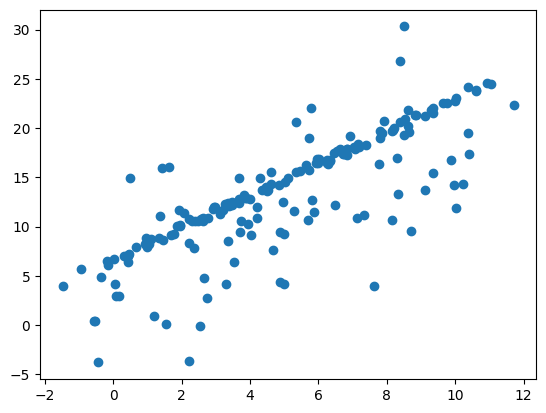

In [271]:
plt.scatter(x, y)

The same x values! Skipping...
[-0.15491396  4.53030121] [ 6.11719859 13.75654302]


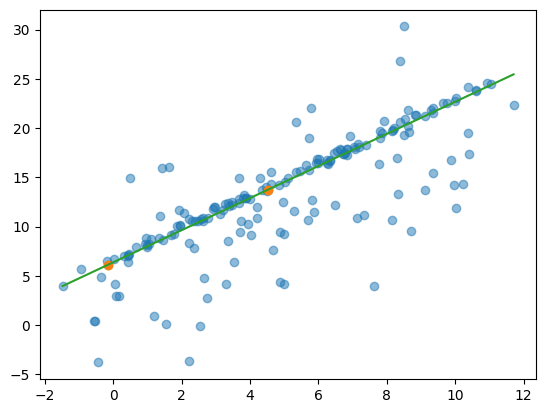

In [272]:
r_idx = np.random.choice(range(len(x)), 2, replace=False)
rx, ry = x[r_idx], y[r_idx]
if rx[0] != rx[1]:
    print("The same x values! Skipping...")
    # continue

print(rx, ry)
a, b = np.polyfit(rx, ry, 1)
plt.scatter(x, y, alpha=0.5)
plt.scatter(rx, ry)
lx = np.array([x.min(), x.max()])
ly = a*lx + b
plt.plot(lx, ly, color="tab:green")

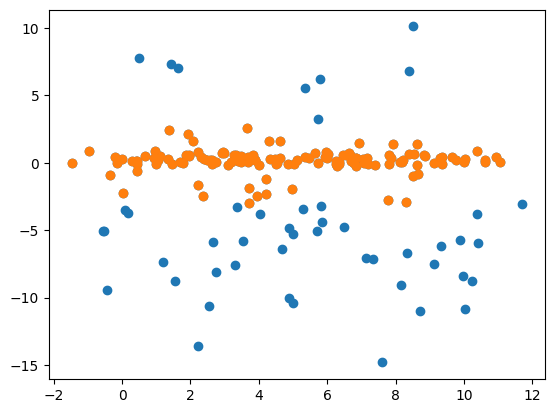

In [273]:
tau = 3.0
err = y - (a*x + b)
plt.scatter(x, err)

mae = (err**2).mean()

C_idx = np.abs(err) <= tau
C = err[C_idx]
C_x = x[C_idx]
plt.scatter(C_x, C)

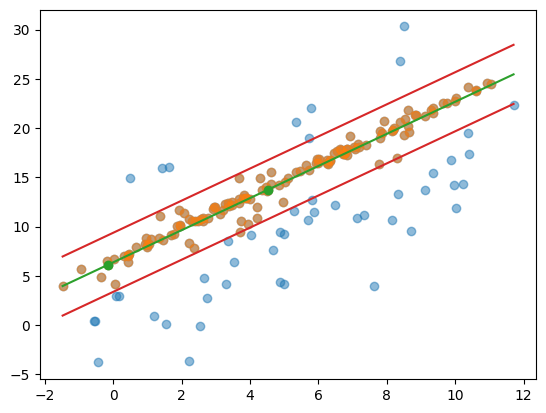

In [274]:
plt.scatter(x, y, alpha=0.5)
plt.scatter(C_x, y[C_idx], alpha=0.5)
plt.scatter(rx, ry)
lx = np.array([x.min(), x.max()])
ly = a*lx + b
plt.plot(lx, ly, color="tab:green")
plt.plot(lx, ly-tau, color="tab:red")
plt.plot(lx, ly+tau, color="tab:red")

In [275]:
C.shape

(132,)

In [276]:
trials.iloc[0]

a          1.590828
b          6.487286
C        133.000000
MAE       14.859023
index      0.000000
Name: 0, dtype: float64

In [277]:
rows = []

rows.append({"a": a, "b": b, "C": len(C), "MAE": mae})
rows.append({"a": 3, "b": b, "C": len(C), "MAE": mae-0.1})
rows.append({"a": 4, "b": b, "C": len(C), "MAE": mae-0.1})
rows.append({"a": 4, "b": b, "C": len(C), "MAE": mae+0.1})
rows.append({"a": 1, "b": 2, "C": 30, "MAE": 1})
# rows.append({"a": 1, "b": 2, "C": 600, "MAE": 1})

trials = pd.DataFrame(rows)
trials["index"] = trials.index

trials

,a,b,C,MAE,index
0,1.630522,6.369789,132,15.094304,0
1,3.000000,6.369789,132,14.994304,1
2,4.000000,6.369789,132,14.994304,2
3,4.000000,6.369789,132,15.194304,3
4,1.000000,2.000000,30,1.000000,4


In [278]:
trials_sorted = trials.sort_values(by=["C", "MAE", "index"], ascending=[False, True, True])
trials_sorted

,a,b,C,MAE,index
1,3.000000,6.369789,132,14.994304,1
2,4.000000,6.369789,132,14.994304,2
0,1.630522,6.369789,132,15.094304,0
3,4.000000,6.369789,132,15.194304,3
4,1.000000,2.000000,30,1.000000,4


In [279]:
best_row = trials_sorted.iloc[0]
best_a = best_row["a"]
best_b = best_row["b"]
best_a, best_b

(3.0, 6.369789138809756)

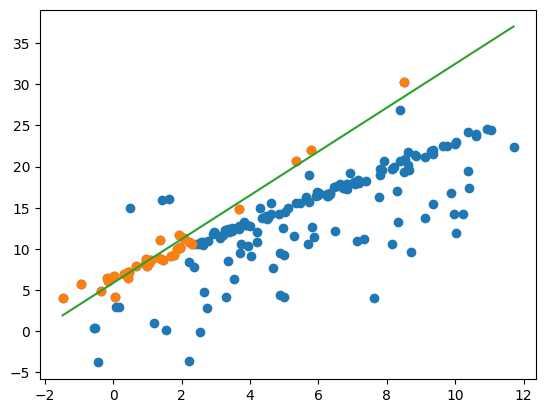

In [280]:
err = y - (best_a*x + best_b)
# plt.scatter(x, err)

C_idx = np.abs(err) <= tau
C = err[C_idx]
inline_x = x[C_idx]
inline_y = y[C_idx]

final_a, final_b = np.polyfit(inline_x, inline_y, 1)
# lx = np.array([x.min, x.max()])
ly = final_a*lx + final_b

plt.scatter(x, y)
plt.scatter(inline_x, inline_y)
plt.plot(lx, ly, color="tab:green")